Training shape: (22083, 45)
Testing shape: (9463, 43)


/tmp/ipykernel_801/345070017.py:36: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_df[col] = test_df[col].replace(


=== CLASS-WISE MISCLASSIFICATION ANALYSIS ===


,Disorder,Precision,Recall,F1_Score,Actual_Cases,False_Negatives,False_Positives
0,Mitochondrial genetic inheritance disorders,0.657,0.371,0.474,1938,1219,375
1,Multifactorial genetic inheritance disorders,0.300,0.849,0.444,397,60,785
2,Single-gene inheritance diseases,0.407,0.440,0.423,1458,816,935



=== MOST COMMON MISCLASSIFICATIONS ===


,Actual_Disorder,Predicted_As,Error_Count
0,Mitochondrial genetic inheritance disorders,Single-gene inheritance diseases,901
1,Single-gene inheritance diseases,Multifactorial genetic inheritance disorders,467
2,Single-gene inheritance diseases,Mitochondrial genetic inheritance disorders,349
3,Mitochondrial genetic inheritance disorders,Multifactorial genetic inheritance disorders,318
4,Multifactorial genetic inheritance disorders,Single-gene inheritance diseases,34
5,Multifactorial genetic inheritance disorders,Mitochondrial genetic inheritance disorders,26


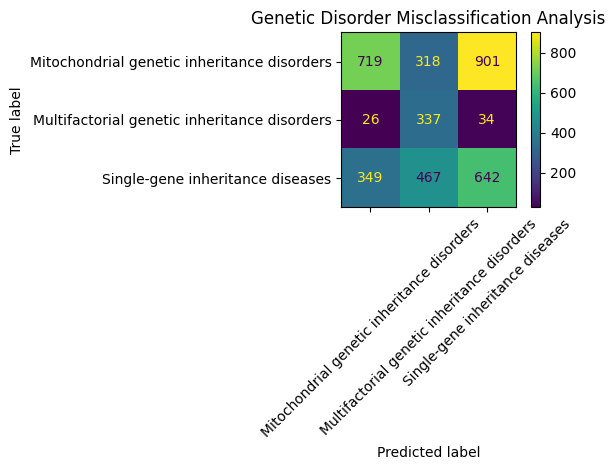


Total validation records: 3793
Incorrect predictions: 2095
Correct predictions: 1698
Misclassification rate: 0.5523
Saved: misclassified_records.csv

Accuracy: 0.4476667545478513

Classification Report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.66      0.37      0.47      1938
Multifactorial genetic inheritance disorders       0.30      0.85      0.44       397
            Single-gene inheritance diseases       0.41      0.44      0.42      1458

                                    accuracy                           0.45      3793
                                   macro avg       0.45      0.55      0.45      3793
                                weighted avg       0.52      0.45      0.45      3793



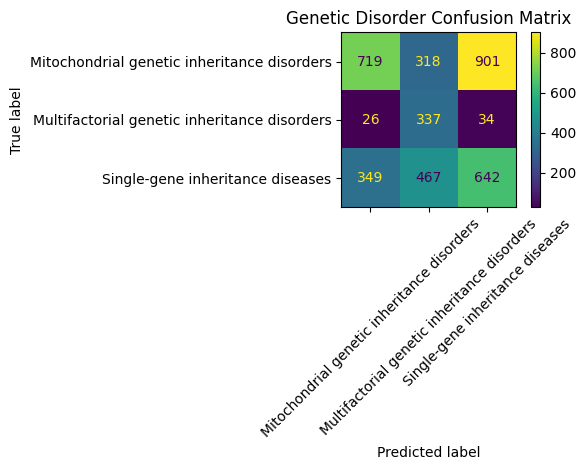


5-Fold Macro F1 Scores: [0.4419503  0.43506287 0.45730925 0.45280541 0.45148642]
Mean Macro F1: 0.44772285171541437

Model saved successfully!


In [1]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Load the training and testing datasets
train_df = pd.read_csv("/content/train_genetic_disorders.csv")
test_df = pd.read_csv("/content/test_genetic_disorders.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

# 2. Handle special missing-value codes
train_df = train_df.replace(-99, np.nan)
test_df = test_df.replace(-99, np.nan)

# Standardize symptom values: True/False and 1/0
symptom_cols = [f"Symptom {i}" for i in range(1, 6)]

for col in symptom_cols:
    train_df[col] = train_df[col].replace(
        {True: 1, False: 0}
    )
    test_df[col] = test_df[col].replace(
        {True: 1, False: 0}
    )

# 3. Remove rows with missing target labels
target = "Genetic Disorder"
train_df = train_df.dropna(subset=[target])

# 4. Separate input features and target
drop_cols = [
    "Patient Id",
    "Patient First Name",
    "Family Name",
    "Father's name",
    "Institute Name",
    "Location of Institute",
    "Disorder Subclass"
]

X = train_df.drop(
    columns=[target] + drop_cols,
    errors="ignore"
)
y = train_df[target]

# 5. Identify numerical and categorical columns
num_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = X.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

# 6. Create preprocessing pipelines
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# 7. Create the complete ML pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

# 8. Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 9. Train the model
model.fit(X_train, y_train)

# 10. Evaluate the model
y_pred = model.predict(X_val)


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

# Step 1: Get actual and predicted values
actual = np.asarray(y_val)
predicted = np.asarray(y_pred)

labels = list(model.classes_)

# Step 2: Calculate class-wise performance
precision, recall, f1, support = precision_recall_fscore_support(
    actual,
    predicted,
    labels=labels,
    zero_division=0
)

cm = confusion_matrix(actual, predicted, labels=labels)

true_positives = np.diag(cm)
false_negatives = cm.sum(axis=1) - true_positives
false_positives = cm.sum(axis=0) - true_positives

analysis_report = pd.DataFrame({
    "Disorder": labels,
    "Precision": precision.round(3),
    "Recall": recall.round(3),
    "F1_Score": f1.round(3),
    "Actual_Cases": support,
    "False_Negatives": false_negatives,
    "False_Positives": false_positives
})

print("=== CLASS-WISE MISCLASSIFICATION ANALYSIS ===")
display(analysis_report)

# Step 3: Find the most frequently confused class pairs
error_matrix = cm.copy()
np.fill_diagonal(error_matrix, 0)

error_pairs = []

for i in range(len(labels)):
    for j in range(len(labels)):
        if error_matrix[i, j] > 0:
            error_pairs.append({
                "Actual_Disorder": labels[i],
                "Predicted_As": labels[j],
                "Error_Count": int(error_matrix[i, j])
            })

error_pairs_df = pd.DataFrame(error_pairs)

if not error_pairs_df.empty:
    error_pairs_df = error_pairs_df.sort_values(
        "Error_Count", ascending=False
    ).reset_index(drop=True)

print("\n=== MOST COMMON MISCLASSIFICATIONS ===")
display(error_pairs_df.head(10))

# Step 4: Display the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(xticks_rotation=45, values_format="d")

plt.title("Genetic Disorder Misclassification Analysis")
plt.tight_layout()
plt.show()

# Step 5: Save incorrectly classified validation records
error_mask = actual != predicted
error_positions = np.flatnonzero(error_mask)

misclassified_records = X_val.iloc[error_positions].copy()
misclassified_records = misclassified_records.reset_index(drop=True)

misclassified_records.insert(0, "Actual_Disorder", actual[error_mask])
misclassified_records.insert(
    1, "Predicted_Disorder", predicted[error_mask]
)

misclassified_records.to_csv(
    "misclassified_records.csv", index=False
)

print("\nTotal validation records:", len(actual))
print("Incorrect predictions:", int(error_mask.sum()))
print("Correct predictions:", int((~error_mask).sum()))
print("Misclassification rate:", round(error_mask.mean(), 4))
print("Saved: misclassified_records.csv")


print("\nAccuracy:", accuracy_score(y_val, y_pred))
print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))

# 11. Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    xticks_rotation=45
)
plt.title("Genetic Disorder Confusion Matrix")
plt.tight_layout()
plt.show()

# 12. Perform 5-fold cross-validation
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="f1_macro"
)

print("\n5-Fold Macro F1 Scores:", cv_scores)
print("Mean Macro F1:", cv_scores.mean())

# 13. Save the trained pipeline
joblib.dump(model, "genetic_disorder_model.pkl")

print("\nModel saved successfully!")


In [2]:
for col in symptom_cols:
    train_df[col] = train_df[col].map({
        True: 1,
        False: 0,
        1.0: 1,
        0.0: 0
    })
    test_df[col] = test_df[col].map({
        True: 1,
        False: 0,
        1.0: 1,
        0.0: 0
    })

In [3]:
print(train_df["Genetic Disorder"].value_counts(dropna=False))


Genetic Disorder
Mitochondrial genetic inheritance disorders     9686
Single-gene inheritance diseases                7291
Multifactorial genetic inheritance disorders    1985
Name: count, dtype: int64


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

# Baseline model
baseline = DummyClassifier(strategy="most_frequent")

baseline_scores = cross_val_score(
    baseline, X, y, cv=5, scoring="f1_macro"
)

print("Baseline Macro F1:", baseline_scores.mean())
print("Logistic Regression Macro F1:", cv_scores.mean())

Baseline Macro F1: 0.22540258644012162
Logistic Regression Macro F1: 0.44772285171541437


In [5]:

# Unique Feature: Misclassification Pattern Discovery

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert actual and predicted labels into arrays
actual = np.asarray(y_val)
predicted = np.asarray(y_pred)

# Identify the main error pattern
actual_class = "Mitochondrial genetic inheritance disorders"
predicted_class = "Single-gene inheritance diseases"

# Select records with this specific error
error_mask = (
    (actual == actual_class) &
    (predicted == predicted_class)
)

# Select correctly predicted records of the same actual class
correct_mask = (
    (actual == actual_class) &
    (predicted == actual_class)
)

error_records = X_val.iloc[np.flatnonzero(error_mask)].copy()
correct_records = X_val.iloc[np.flatnonzero(correct_mask)].copy()

print("=== ERROR PATTERN DISCOVERY ===")
print("Misclassified records:", len(error_records))
print("Correctly classified comparison records:", len(correct_records))

# Compare missing-value percentages
if len(error_records) > 0 and len(correct_records) > 0:

    comparison = pd.DataFrame({
        "Error_Group_Missing_%":
            error_records.isna().mean() * 100,
        "Correct_Group_Missing_%":
            correct_records.isna().mean() * 100
    })

    comparison["Difference_%"] = (
        comparison["Error_Group_Missing_%"] -
        comparison["Correct_Group_Missing_%"]
    )

    comparison = comparison.sort_values(
        "Difference_%", key=abs, ascending=False
    )

    print("\n=== FEATURES WITH DIFFERENT MISSINGNESS ===")
    display(comparison.head(15).round(2))

    # Compare numerical feature averages
    numeric_cols = X_val.select_dtypes(
        include="number"
    ).columns.tolist()

    if numeric_cols:
        numeric_comparison = pd.DataFrame({
            "Error_Group_Mean":
                error_records[numeric_cols].mean(),
            "Correct_Group_Mean":
                correct_records[numeric_cols].mean()
        })

        numeric_comparison["Mean_Difference"] = (
            numeric_comparison["Error_Group_Mean"] -
            numeric_comparison["Correct_Group_Mean"]
        )

        print("\n=== NUMERICAL FEATURE COMPARISON ===")
        display(
            numeric_comparison.sort_values(
                "Mean_Difference",
                key=abs,
                ascending=False
            ).head(15).round(3)
        )

else:
    print("Not enough records for comparison.")


=== ERROR PATTERN DISCOVERY ===
Misclassified records: 901
Correctly classified comparison records: 719

=== FEATURES WITH DIFFERENT MISSINGNESS ===


,Error_Group_Missing_%,Correct_Group_Missing_%,Difference_%
Symptom 2,4.99,13.63,-8.64
Blood test result,11.43,3.89,7.54
Autopsy shows birth defect (if applicable),16.76,23.92,-7.16
Gender,7.21,11.54,-4.33
Maternal gene,9.99,13.77,-3.78
H/O radiation exposure (x-ray),11.99,8.34,3.64
Father's age,24.86,28.23,-3.37
Symptom 5,8.88,11.96,-3.08
Assisted conception IVF/ART,10.65,8.07,2.59
Folic acid details (peri-conceptional),9.10,11.68,-2.58



=== NUMERICAL FEATURE COMPARISON ===


,Error_Group_Mean,Correct_Group_Mean,Mean_Difference
Mother's age,34.616,34.070,0.545
Symptom 2,0.362,0.717,-0.354
Symptom 5,0.436,0.231,0.205
White Blood cell count (thousand per microliter),7.545,7.364,0.181
Patient Age,7.025,6.847,0.178
No. of previous abortion,1.990,2.153,-0.163
Symptom 1,0.526,0.628,-0.102
Symptom 3,0.409,0.486,-0.077
Symptom 4,0.393,0.446,-0.053
Father's age,41.703,41.738,-0.035


In [6]:

from scipy.stats import mannwhitneyu, fisher_exact
import pandas as pd
import numpy as np

# Collect statistical test results
results = []

# Test every feature
for col in error_records.columns:

    error_values = error_records[col]
    correct_values = correct_records[col]

    # 1. Compare missing-value percentages
    error_missing = int(error_values.isna().sum())
    correct_missing = int(correct_values.isna().sum())

    contingency_table = [
        [error_missing, len(error_values) - error_missing],
        [correct_missing, len(correct_values) - correct_missing]
    ]

    _, missing_p = fisher_exact(contingency_table)

    results.append({
        "Feature": col,
        "Test": "Missingness",
        "Error_Group_Value": round(
            error_missing / len(error_values) * 100, 2
        ),
        "Correct_Group_Value": round(
            correct_missing / len(correct_values) * 100, 2
        ),
        "P_Value": missing_p
    })

    # 2. Compare numeric feature distributions
    if pd.api.types.is_numeric_dtype(error_values):

        e = error_values.dropna()
        c = correct_values.dropna()

        if len(e) > 0 and len(c) > 0:
            _, p_value = mannwhitneyu(
                e, c, alternative="two-sided"
            )

            results.append({
                "Feature": col,
                "Test": "Numeric distribution",
                "Error_Group_Value": round(e.median(), 3),
                "Correct_Group_Value": round(c.median(), 3),
                "P_Value": p_value
            })

# Create results table
stats_df = pd.DataFrame(results)

# Benjamini-Hochberg correction
p_values = stats_df["P_Value"].to_numpy()
n = len(p_values)
order = np.argsort(p_values)
sorted_p = p_values[order]

adjusted_sorted = sorted_p * n / np.arange(1, n + 1)
adjusted_sorted = np.minimum.accumulate(
    adjusted_sorted[::-1]
)[::-1]
adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

adjusted_p = np.empty(n)
adjusted_p[order] = adjusted_sorted

stats_df["Adjusted_P_Value"] = adjusted_p
stats_df["Potential_Signal"] = (
    stats_df["Adjusted_P_Value"] < 0.05
)

stats_df = stats_df.sort_values(
    "Adjusted_P_Value"
).reset_index(drop=True)

print("=== STATISTICALLY TESTED ERROR PATTERNS ===")
display(stats_df.head(20).round(4))

stats_df.to_csv(
    "misclassification_statistical_analysis.csv",
    index=False
)

print("Saved: misclassification_statistical_analysis.csv")


=== STATISTICALLY TESTED ERROR PATTERNS ===


,Feature,Test,Error_Group_Value,Correct_Group_Value,P_Value,Adjusted_P_Value,Potential_Signal
0,Symptom 2,Numeric distribution,0.00,1.00,0.0000,0.0000,True
1,Symptom 5,Numeric distribution,0.00,0.00,0.0000,0.0000,True
2,Symptom 2,Missingness,4.99,13.63,0.0000,0.0000,True
3,Blood test result,Missingness,11.43,3.89,0.0000,0.0000,True
4,Symptom 1,Numeric distribution,1.00,1.00,0.0001,0.0007,True
5,Autopsy shows birth defect (if applicable),Missingness,16.76,23.92,0.0004,0.0032,True
6,Symptom 3,Numeric distribution,0.00,0.00,0.0027,0.0201,True
7,Gender,Missingness,7.21,11.54,0.0031,0.0205,True
8,H/O radiation exposure (x-ray),Missingness,11.99,8.34,0.0174,0.1026,False
9,Maternal gene,Missingness,9.99,13.77,0.0195,0.1035,False


Saved: misclassification_statistical_analysis.csv


GENETIC DISORDER - ERROR INSIGHT REPORT

Total comparisons tested: 53
Potential statistical signals: 8

Potential error-associated patterns:

Feature: Symptom 2
Analysis: Numeric distribution
Error group value: 0.0
Correct group value: 1.0
Adjusted p-value: 1.70308e-39
----------------------------------------
Feature: Symptom 5
Analysis: Numeric distribution
Error group value: 0.0
Correct group value: 0.0
Adjusted p-value: 9.09075e-15
----------------------------------------
Feature: Symptom 2
Analysis: Missingness
Error group value: 4.99
Correct group value: 13.63
Adjusted p-value: 3.22116e-08
----------------------------------------
Feature: Blood test result
Analysis: Missingness
Error group value: 11.43
Correct group value: 3.89
Adjusted p-value: 1.78062e-07
----------------------------------------
Feature: Symptom 1
Analysis: Numeric distribution
Error group value: 1.0
Correct group value: 1.0
Adjusted p-value: 0.000739241
----------------------------------------
Feature: Autopsy 

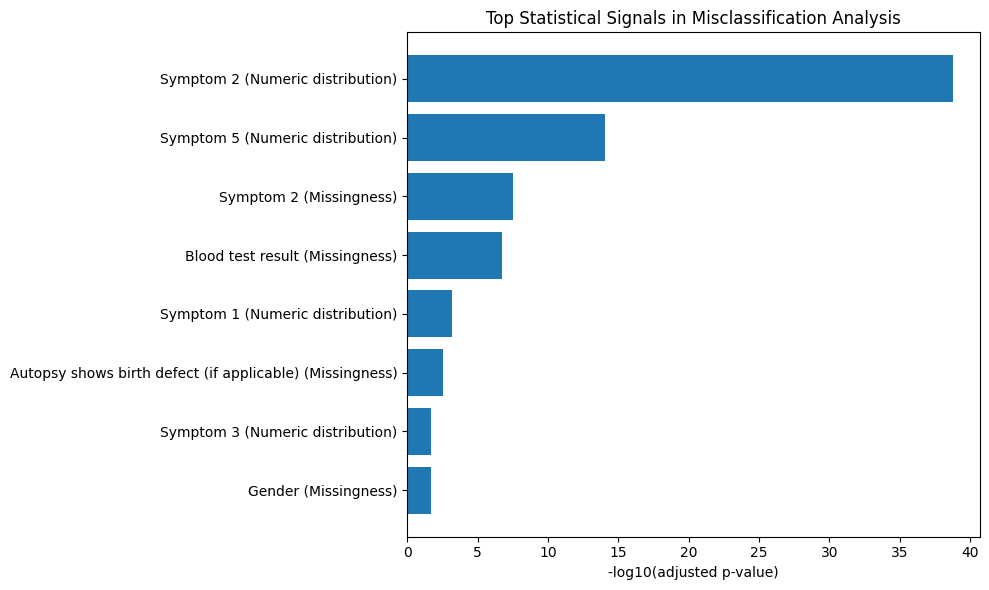


Report saved: genetic_disorder_error_insights.csv


In [7]:

# Automatic Misclassification Insight Report

import pandas as pd
import matplotlib.pyplot as plt

# Select statistically significant comparisons
significant = stats_df[
    stats_df["Adjusted_P_Value"] < 0.05
].copy()

print("=" * 60)
print("GENETIC DISORDER - ERROR INSIGHT REPORT")
print("=" * 60)

print("\nTotal comparisons tested:", len(stats_df))
print("Potential statistical signals:", len(significant))

if significant.empty:
    print("\nNo comparisons passed the adjusted p-value threshold.")
else:
    print("\nPotential error-associated patterns:\n")

    for _, row in significant.iterrows():
        feature = row["Feature"]
        test = row["Test"]
        error_value = row["Error_Group_Value"]
        correct_value = row["Correct_Group_Value"]
        p_value = row["Adjusted_P_Value"]

        print(f"Feature: {feature}")
        print(f"Analysis: {test}")
        print(f"Error group value: {error_value}")
        print(f"Correct group value: {correct_value}")
        print(f"Adjusted p-value: {p_value:.6g}")
        print("-" * 40)

# Visualize the top significant results
top_results = significant.head(10).copy()

if not top_results.empty:
    top_results["Comparison"] = (
        top_results["Feature"] + " (" + top_results["Test"] + ")"
    )

    # Show adjusted p-values on a negative log scale.
    # Clipping prevents log(0) when values are extremely small.
    top_results["-log10 adjusted p"] = -(
        top_results["Adjusted_P_Value"].clip(lower=1e-300)
        .apply(lambda p: __import__("math").log10(p))
    )

    top_results = top_results.sort_values("-log10 adjusted p")

    plt.figure(figsize=(10, 6))
    plt.barh(
        top_results["Comparison"],
        top_results["-log10 adjusted p"]
    )
    plt.xlabel("-log10(adjusted p-value)")
    plt.title("Top Statistical Signals in Misclassification Analysis")
    plt.tight_layout()
    plt.show()

# Save a readable report
significant.to_csv(
    "genetic_disorder_error_insights.csv",
    index=False
)

print("\nReport saved: genetic_disorder_error_insights.csv")


In [8]:

# Validate the features identified by the analysis

features_to_check = [
    "Symptom 1",
    "Symptom 2",
    "Symptom 3",
    "Symptom 5",
    "Blood test result"
]

print("=== FEATURE VALUE VALIDATION ===")

for col in features_to_check:
    if col in X_val.columns:
        print(f"\n{col}")
        print("Data type:", X_val[col].dtype)
        print("Unique values:")
        print(X_val[col].value_counts(dropna=False).head(10))

        if pd.api.types.is_numeric_dtype(X_val[col]):
            print("-99 values:", (X_val[col] == -99).sum())


=== FEATURE VALUE VALIDATION ===

Symptom 1
Data type: float64
Unique values:
Symptom 1
1.0    2092
0.0    1390
NaN     311
Name: count, dtype: int64
-99 values: 0

Symptom 2
Data type: float64
Unique values:
Symptom 2
1.0    1936
0.0    1485
NaN     372
Name: count, dtype: int64
-99 values: 0

Symptom 3
Data type: float64
Unique values:
Symptom 3
1.0    1844
0.0    1592
NaN     357
Name: count, dtype: int64
-99 values: 0

Symptom 5
Data type: float64
Unique values:
Symptom 5
0.0    1843
1.0    1590
NaN     360
Name: count, dtype: int64
-99 values: 0

Blood test result
Data type: object
Unique values:
Blood test result
slightly abnormal    891
inconclusive         885
normal               867
abnormal             836
NaN                  314
Name: count, dtype: int64


In [9]:

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Compare category distributions between the two groups
group_results = []

# Treat symptoms as categories even though they are numeric 0/1
symptom_cols = [
    "Symptom 1", "Symptom 2", "Symptom 3",
    "Symptom 4", "Symptom 5"
]

categorical_cols = [
    col for col in X_val.columns
    if (
        X_val[col].dtype == "object"
        or X_val[col].dtype.name == "category"
        or col in symptom_cols
    )
]

for col in categorical_cols:
    error_values = error_records[col].fillna("Missing").astype(str)
    correct_values = correct_records[col].fillna("Missing").astype(str)

    combined = pd.DataFrame({
        "Group": (
            ["Error"] * len(error_values)
            + ["Correct"] * len(correct_values)
        ),
        "Value": list(error_values) + list(correct_values)
    })

    table = pd.crosstab(combined["Group"], combined["Value"])

    # Need at least two categories to compare
    if table.shape[1] < 2:
        continue

    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)

    cramers_v = (
        np.sqrt(chi2 / (n * min_dimension))
        if min_dimension > 0 and n > 0
        else np.nan
    )

    group_results.append({
        "Feature": col,
        "Categories": table.shape[1],
        "Chi_square_p_value": p_value,
        "Cramers_V": cramers_v,
        "Smallest_expected_count": expected.min()
    })

category_results = pd.DataFrame(group_results)

if not category_results.empty:
    # Benjamini-Hochberg correction for multiple comparisons
    p = category_results["Chi_square_p_value"].to_numpy()
    n_tests = len(p)
    order = np.argsort(p)
    sorted_p = p[order]

    adjusted_sorted = sorted_p * n_tests / np.arange(1, n_tests + 1)
    adjusted_sorted = np.minimum.accumulate(
        adjusted_sorted[::-1]
    )[::-1]
    adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

    adjusted = np.empty(n_tests)
    adjusted[order] = adjusted_sorted

    category_results["Adjusted_P_Value"] = adjusted
    category_results["Potential_Signal"] = adjusted < 0.05

    category_results = category_results.sort_values(
        "Adjusted_P_Value"
    ).reset_index(drop=True)

    print("=== CATEGORY PATTERN ANALYSIS ===")
    display(category_results.round(4))

    # Detailed distribution for Blood test result
    if "Blood test result" in X_val.columns:
        distribution = pd.DataFrame({
            "Error_Group": error_records["Blood test result"]
                .fillna("Missing").astype(str).value_counts(
                    normalize=True
                ) * 100,
            "Correct_Group": correct_records["Blood test result"]
                .fillna("Missing").astype(str).value_counts(
                    normalize=True
                ) * 100
        }).fillna(0)

        print("\n=== BLOOD TEST RESULT DISTRIBUTION (%) ===")
        display(distribution.round(2))

    category_results.to_csv(
        "categorical_error_pattern_analysis.csv",
        index=False
    )
    print("Saved: categorical_error_pattern_analysis.csv")
else:
    print("No suitable categorical features found.")


=== CATEGORY PATTERN ANALYSIS ===


,Feature,Categories,Chi_square_p_value,Cramers_V,Smallest_expected_count,Adjusted_P_Value,Potential_Signal
0,Blood test result,5,0.0000,0.4018,58.1414,0.0000,True
1,Symptom 2,3,0.0000,0.3649,63.4673,0.0000,True
2,Gender,4,0.0000,0.2287,65.6864,0.0000,True
3,Symptom 5,3,0.0000,0.2085,73.6753,0.0000,True
4,Birth asphyxia,5,0.0000,0.1759,69.2370,0.0000,True
5,Follow-up,3,0.0000,0.1625,69.6809,0.0000,True
6,Genes in mother's side,2,0.0000,0.1528,322.6623,0.0000,True
7,Maternal gene,3,0.0000,0.1588,83.8833,0.0000,True
8,H/O radiation exposure (x-ray),5,0.0000,0.1659,74.5630,0.0000,True
9,Heart Rate (rates/min,3,0.0000,0.1362,63.4673,0.0000,True



=== BLOOD TEST RESULT DISTRIBUTION (%) ===


,Error_Group,Correct_Group
Blood test result,,
Missing,11.43,3.89
abnormal,24.53,16.69
inconclusive,20.87,29.49
normal,10.65,38.39
slightly abnormal,32.52,11.54


Saved: categorical_error_pattern_analysis.csv


In [10]:
print("Misclassified Records - Symptom 2")
print(error_records["Symptom 2"].value_counts(dropna=False))

print("\nCorrectly Classified Records - Symptom 2")
print(correct_records["Symptom 2"].value_counts(dropna=False))


Misclassified Records - Symptom 2
Symptom 2
0.0    546
1.0    310
NaN     45
Name: count, dtype: int64

Correctly Classified Records - Symptom 2
Symptom 2
1.0    445
0.0    176
NaN     98
Name: count, dtype: int64


In [11]:
print("Misclassified Records (%)")
print(
    error_records["Symptom 2"]
    .value_counts(normalize=True, dropna=False) * 100
)

print("\nCorrectly Classified Records (%)")
print(
    correct_records["Symptom 2"]
    .value_counts(normalize=True, dropna=False) * 100
)


Misclassified Records (%)
Symptom 2
0.0    60.599334
1.0    34.406215
NaN     4.994451
Name: proportion, dtype: float64

Correctly Classified Records (%)
Symptom 2
1.0    61.891516
0.0    24.478442
NaN    13.630042
Name: proportion, dtype: float64


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

rf_model = clone(model)

rf_model.set_params(
    classifier=RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_val)

print("Random Forest Accuracy:",
      accuracy_score(y_val, rf_pred))

print("Random Forest Macro F1:",
      f1_score(y_val, rf_pred, average="macro"))


Random Forest Accuracy: 0.5721065119957817
Random Forest Macro F1: 0.41754076649108546


In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_val, rf_pred, zero_division=0))


                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.58      0.90      0.71      1938
Multifactorial genetic inheritance disorders       0.48      0.12      0.20       397
            Single-gene inheritance diseases       0.55      0.26      0.35      1458

                                    accuracy                           0.57      3793
                                   macro avg       0.54      0.43      0.42      3793
                                weighted avg       0.56      0.57      0.52      3793



In [14]:
rf_balanced = clone(model)

rf_balanced.set_params(
    classifier=RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
)

rf_balanced.fit(X_train, y_train)

rf_balanced_pred = rf_balanced.predict(X_val)

print(classification_report(
    y_val,
    rf_balanced_pred,
    zero_division=0
))

print("Macro F1:",
      f1_score(y_val, rf_balanced_pred, average="macro"))


                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.57      0.91      0.70      1938
Multifactorial genetic inheritance disorders       0.52      0.12      0.20       397
            Single-gene inheritance diseases       0.56      0.24      0.34      1458

                                    accuracy                           0.57      3793
                                   macro avg       0.55      0.43      0.41      3793
                                weighted avg       0.56      0.57      0.51      3793

Macro F1: 0.4142615139762855


In [15]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.base import clone
from sklearn.metrics import classification_report, f1_score, accuracy_score

et_model = clone(model)

et_model.set_params(
    classifier=ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

et_model.fit(X_train, y_train)

et_pred = et_model.predict(X_val)

print(classification_report(y_val, et_pred, zero_division=0))
print("Accuracy:", accuracy_score(y_val, et_pred))
print("Macro F1:", f1_score(y_val, et_pred, average="macro"))


                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.59      0.86      0.70      1938
Multifactorial genetic inheritance disorders       0.49      0.17      0.25       397
            Single-gene inheritance diseases       0.56      0.32      0.41      1458

                                    accuracy                           0.58      3793
                                   macro avg       0.55      0.45      0.45      3793
                                weighted avg       0.57      0.58      0.54      3793

Accuracy: 0.582652254152386
Macro F1: 0.4533986677376411


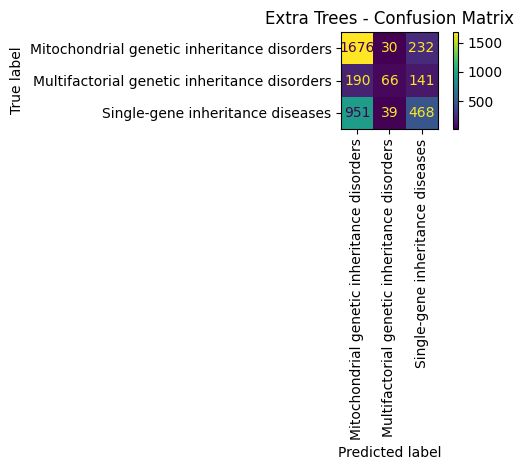

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    et_pred,
    xticks_rotation="vertical"
)

plt.title("Extra Trees - Confusion Matrix")
plt.tight_layout()
plt.show()


In [17]:
import joblib

joblib.dump(et_model, "genetic_disorder_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [18]:
import joblib
from sklearn.metrics import accuracy_score, f1_score

# Load the saved model
loaded_model = joblib.load("genetic_disorder_model.pkl")

# Test the saved model
loaded_pred = loaded_model.predict(X_val)

print("Model loaded successfully!")
print("Accuracy:", accuracy_score(y_val, loaded_pred))
print("Macro F1:", f1_score(y_val, loaded_pred, average="macro"))

print("Predictions match:", (loaded_pred == et_pred).all())


Model loaded successfully!
Accuracy: 0.582652254152386
Macro F1: 0.4533986677376411
Predictions match: True


In [19]:
from google.colab import files
files.download('genetic_disorder_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 18.1 MB/s eta 0:00:00


In [21]:
print("Available models:")
print("Logistic Regression model:", "model" in globals())
print("Extra Trees model:", "et_model" in globals())
print("Training features:", len(X_train.columns))
print("Feature names:")
print(X_train.columns.tolist()
)

Available models:
Logistic Regression model: True
Extra Trees model: True
Training features: 37
Feature names:
['Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', "Mother's age", "Father's age", 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5']


In [24]:
import joblib

# Save the Logistic Regression pipeline
joblib.dump(model, "logistic_regression_model.pkl")

# Verify the saved model
loaded_model = joblib.load("logistic_regression_model.pkl")

print("Logistic Regression model saved successfully!")
print("Number of input features:", len(X_train.columns))
print("Model classes:", loaded_model.classes_)

Logistic Regression model saved successfully!
Number of input features: 37
Model classes: ['Mitochondrial genetic inheritance disorders'
 'Multifactorial genetic inheritance disorders'
 'Single-gene inheritance diseases']


In [22]:
!pip install flask

In [72]:

from flask import Flask, request, jsonify
import pandas as pd
import joblib
import json
import os

app = Flask(__name__)

# Load the saved Extra Trees pipeline
model = joblib.load("genetic_disorder_model.pkl")

# Load feature information
with open("feature_info.json", "r") as file:
    feature_info = json.load(file)

# Extract the exact feature names in training order
if isinstance(feature_info, dict) and "features" in feature_info:
    feature_names = [
        item["name"] if isinstance(item, dict) else item
        for item in feature_info["features"]
    ]
else:
    feature_names = list(feature_info.keys())

print("Model loaded successfully!")
print("Number of features:", len(feature_names))


@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "message": "Genetic Disorder Prediction API is running",
        "model": "Extra Trees",
        "number_of_features": len(feature_names)
    })


@app.route("/predict", methods=["POST"])
def predict():
    try:
        data = request.get_json(silent=True)

        if not isinstance(data, dict):
            return jsonify({
                "error": "Send patient details as JSON"
            }), 400

        # Check required features
        missing = [
            col for col in feature_names
            if col not in data
        ]

        if missing:
            return jsonify({
                "error": "Missing required features",
                "missing_features": missing
            }), 400

        # Keep the exact feature order
        patient = pd.DataFrame(
            [[data[col] for col in feature_names]],
            columns=feature_names
        )

        # Predict the category
        prediction = model.predict(patient)[0]

        result = {
            "predicted_category": str(prediction)
        }

        # Return class probabilities if supported
        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(patient)[0]

            result["probabilities"] = {
                str(label): round(float(prob), 4)
                for label, prob in zip(
                    model.classes_,
                    probabilities
                )
            }

        return jsonify(result), 200

    except Exception as e:
        return jsonify({
            "error": str(e)
        }), 400


if __name__ == "__main__":
    app.run(
        host="0.0.0.0",
        port=5000,
        debug=False
    )


Model loaded successfully!
Number of features: 37
 * Serving Flask app '__main__'
 * Debug mode: off


Address already in use
Port 5000 is in use by another program. Either identify and stop that program, or start the server with a different port.
ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/werkzeug/serving.py", line 763, in __init__
    self.server_bind()
    ~~~~~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/http/server.py", line 140, in server_bind
    socketserver.TCPServer.server_bind(self)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^
  File "/usr/lib/python3.13/socketserver.py", line 478, in server_bind
    self.socket.bind(self.server_address)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
OSError: [Errno 98] Address already in use

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_801/2195361952.py", line 94, in <cell line: 0>
    app.run(
    ~~~~~~~^
        host="0.0.0.0",
        ^^^^^^^^^^^^^^^
      

TypeError: object of type 'NoneType' has no len()

In [70]:
from threading import Thread

def run_flask():
    app.run(host="0.0.0.0", port=5001, debug=False, use_reloader=False)

flask_thread = Thread(target=run_flask, daemon=True)
flask_thread.start()

 * Serving Flask app '__main__'
 * Debug mode: off


In [27]:
import requests

response = requests.get("http://127.0.0.1:5000/", timeout=5)

print("Status code:", response.status_code)
print("Response:", response.json())

INFO:werkzeug:127.0.0.1 - - [20/Oct/2026 13:41:18] "GET / HTTP/1.1" 200 -


Status code: 200
Response: {'message': 'Genetic Disorder Prediction API is running'}


In [28]:
import requests

# Take one patient record from validation data
sample = X_val.iloc[0].to_dict()

# Convert NumPy values into JSON-compatible Python values
sample = {
    key: value.item() if hasattr(value, "item") else value
    for key, value in sample.items()
}

response = requests.post(
    "http://127.0.0.1:5000/predict",
    json=sample,
    timeout=30
)

print("Status code:", response.status_code)
print("Prediction result:")
print(response.json())

INFO:werkzeug:127.0.0.1 - - [20/Oct/2026 13:41:21] "POST /predict HTTP/1.1" 200 -


Status code: 200
Prediction result:
{'predicted_category': 'Mitochondrial genetic inheritance disorders', 'probabilities': {'Mitochondrial genetic inheritance disorders': 0.4321, 'Multifactorial genetic inheritance disorders': 0.1643, 'Single-gene inheritance diseases': 0.4035}}


In [74]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import requests
import json
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Genetic Disorder Classification",
    page_icon="🧬",
    layout="wide"
)

st.title("🧬 Genetic Disorder Risk Classification System")
st.write(
    "Educational ML prototype for preliminary genetic disorder "
    "category classification. This is not a medical diagnosis."
)

API_URL = "http://127.0.0.1:5000/predict"

with open("feature_info.json", "r") as f:
    feature_info = json.load(f)

st.header("Patient Information")
st.write("Enter the available patient attributes below.")

with st.form("patient_form"):
    patient_data = {}

    for feature, info in feature_info.items():
        if info["type"] == "numeric":
            default = info.get("default", 0.0)
            patient_data[feature] = st.number_input(
                feature,
                value=float(default),
                key=feature
            )
        else:
            options = info.get("options", [])

            if options:
                patient_data[feature] = st.selectbox(
                    feature,
                    options=options,
                    key=feature
                )
            else:
                patient_data[feature] = st.text_input(
                    feature,
                    key=feature
                )

    submitted = st.form_submit_button("Predict Disorder Category")

if submitted:
    try:
        response = requests.post(
            API_URL,
            json=patient_data,
            timeout=60
        )

        if response.status_code == 200:
            result = response.json()

            st.subheader("Prediction Result")
            st.success(result["predicted_category"])

            probabilities = result.get("probabilities", {})

            if probabilities:
                st.subheader("Class Probability Estimates")

                probability_df = pd.DataFrame({
                    "Category": list(probabilities.keys()),
                    "Probability": list(probabilities.values())
                })

                probability_df["Percentage"] = (
                    probability_df["Probability"] * 100
                )

                st.bar_chart(
                    probability_df.set_index("Category")["Percentage"]
                )

                st.dataframe(
                    probability_df[["Category", "Percentage"]],
                    use_container_width=True,
                    hide_index=True
                )

                st.caption(
                    "Probabilities are model estimates and may not be "
                    "calibrated clinical risk values."
                )

        else:
            st.error(f"API error ({response.status_code}): {response.text}")

    except requests.exceptions.RequestException as e:
        st.error(
            "Could not connect to the Flask API. Make sure the API is running."
        )
        st.code(str(e))

st.divider()
st.subheader("Model Performance")

st.write(
    "Use the validation metrics and confusion matrix from your "
    "model evaluation notebook here. The values below should come "
    "from the same saved Logistic Regression model."
)

st.info(
    "Overall accuracy alone is not enough for classification. "
    "Compare per-class precision, recall and F1-score, especially "
    "because the three categories have different sample counts."
)

Overwriting app.py


In [30]:
import os

print("app.py:", os.path.exists("app.py"))
print("feature_info.json:", os.path.exists("feature_info.json"))
print("Model file:", os.path.exists("logistic_regression_model.pkl"))

app.py: True
feature_info.json: False
Model file: True


In [31]:
import json
import pandas as pd

feature_info = {}

for col in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[col]):
        feature_info[col] = {
            "type": "numeric",
            "default": float(X_train[col].median())
        }
    else:
        values = X_train[col].dropna().astype(str).unique().tolist()

        feature_info[col] = {
            "type": "categorical",
            "options": values,
            "default": values[0] if values else ""
        }

with open("feature_info.json", "w") as f:
    json.dump(feature_info, f, indent=2)

print("Feature information saved!")
print("Total features:", len(feature_info))

Feature information saved!
Total features: 37


In [32]:
import os

for filename in [
    "app.py",
    "feature_info.json",
    "logistic_regression_model.pkl"
]:
    print(filename, ":", os.path.exists(filename))


app.py : True
feature_info.json : True
logistic_regression_model.pkl : True


In [34]:
!pip install -q pyngrok

In [35]:
!pip install -q pyngrok

from pyngrok import ngrok

ngrok.set_auth_token("3KrD1WYQFzD8nbbSny9kaY6NtvW_3kBePNnUtmcFd7JndNgHN")

print("ngrok authentication configured!")

ngrok authentication configured!


In [36]:
from pyngrok import ngrok

api_tunnel = ngrok.connect(5000, "http")

print("Flask API URL:", api_tunnel.public_url)

Flask API URL: https://dingo-paprika-uneaten.ngrok-free.dev


In [37]:
from pathlib import Path

file_path = Path("app.py")
code = file_path.read_text()

code = code.replace(
    'API_URL = "http://127.0.0.1:5000/predict"',
    'API_URL = "https://dingo-paprika-uneaten.ngrok-free.dev/predict"'
)

code = code.replace(
    'json=patient_data,\n            timeout=60',
    'json=patient_data,\n            headers={"ngrok-skip-browser-warning": "true"},\n            timeout=60'
)

file_path.write_text(code)

print("Streamlit API URL updated!")
print("API endpoint:", "https://dingo-paprika-uneaten.ngrok-free.dev/predict")

Streamlit API URL updated!
API endpoint: https://dingo-paprika-uneaten.ngrok-free.dev/predict


In [38]:
import requests

url = "https://dingo-paprika-uneaten.ngrok-free.dev/"

try:
    response = requests.get(
        url,
        headers={"ngrok-skip-browser-warning": "true"},
        timeout=20
    )
    print("Status:", response.status_code)
    print("Response:", response.text[:500])
except Exception as e:
    print("Connection error:", e)

INFO:werkzeug:127.0.0.1 - - [20/Oct/2026 13:43:50] "GET / HTTP/1.1" 200 -


Status: 200
Response: {"message":"Genetic Disorder Prediction API is running"}



In [39]:
import subprocess
import time
import requests

# Start Streamlit in the background
streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT
)

# Wait briefly for the server to start
time.sleep(5)

if streamlit_process.poll() is None:
    print("Streamlit process started!")
else:
    print("Streamlit did not start. Check the app file and installation.")

Streamlit process started!


In [40]:
from google.colab.output import eval_js

streamlit_url = eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("Open your Genetic Disorder Classification app:")
print(streamlit_url)

Open your Genetic Disorder Classification app:
https://8501-m-s-kkb-usc1c0-36e540e1j72qm-c.us-central1-0.prod.colab.dev


In [41]:
import requests
import subprocess

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Streamlit status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Streamlit is not responding:", e)

print("\nStreamlit processes:")
subprocess.run(["pgrep", "-af", "streamlit"])

Streamlit status: 200
Response: ok

Streamlit processes:


CompletedProcess(args=['pgrep', '-af', 'streamlit'], returncode=0)

In [42]:
import requests

for path in ["/", "/_stcore/health"]:
    try:
        r = requests.get(
            "http://127.0.0.1:8501" + path,
            timeout=10
        )
        print(path, "Status:", r.status_code)
        print("Response:", r.text[:200])
    except Exception as e:
        print(path, "Error:", e)

/ Status: 200
Response: <!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the Lic
/_stcore/health Status: 200
Response: ok


In [43]:
!ps aux | grep -i '[s]treamlit'

root        5538  9.0  0.5 454284 75116 ?        Sl   13:44   0:03 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


In [44]:
import ast

with open("app.py", "r") as f:
    code = f.read()

try:
    ast.parse(code)
    print("app.py syntax: OK")
except SyntaxError as e:
    print("Syntax error:", e)

print("App file size:", len(code), "characters")

app.py syntax: OK
App file size: 3557 characters


In [45]:
import os
import glob

log_files = glob.glob("/root/.streamlit/logs/*")

print("Log files found:", log_files)

for path in log_files:
    print(f"\n--- {path} ---")
    with open(path, "r", errors="ignore") as f:
        print(f.read()[-5000:])


Log files found: []


In [46]:
import requests

r = requests.get("http://127.0.0.1:8501/", timeout=10)

print("HTTP status:", r.status_code)
print("HTML length:", len(r.text))
print("Contains Streamlit script:", "src=" in r.text)
print(
    "Contains app title:",
    "Genetic Disorder Classification" in r.text
)

HTTP status: 200
HTML length: 6467
Contains Streamlit script: True
Contains app title: False


In [47]:
import subprocess
import time
import requests
import os
import signal

# Stop the existing Streamlit process only
subprocess.run(["pkill", "-f", "streamlit run app.py"], check=False)

CompletedProcess(args=['pkill', '-f', 'streamlit run app.py'], returncode=0)

In [48]:
import subprocess
import time
import requests

log_file = open("/tmp/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--logger.level", "debug"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit running:", streamlit_process.poll() is None)

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Health status:", r.status_code, r.text)
except Exception as e:
    print("Health check error:", e)

with open("/tmp/streamlit.log", "r") as f:
    print("\n--- Startup logs ---")
    print(f.read()[-6000:])

Streamlit running: True
Health status: 200 ok

--- Startup logs ---


2026-10-20 13:45:56.322 No ASGI app assignments found in /content/app.py
2026-10-20 13:45:57.542 Filtered 667 packages down to 2 candidates for component scanning
2026-10-20 13:45:57.542 Scanning 2 candidate packages for component manifests using 2 worker threads
2026-10-20 13:45:57.597 Found 0 component manifests total
2026-10-20 13:45:57.597 No asset roots to watch
2026-10-20 13:45:57.597 File watching not started
2026-10-20 13:45:57.602 Starting new uvloop event loop for server
2026-10-20 13:45:57.602 Starting server...
2026-10-20 13:45:57.653 Starting uvicorn server on 0.0.0.0:8501
2026-10-20 13:45:57.695 Runtime state: RuntimeState.INITIAL -> RuntimeState.NO_SESSIONS_CONNECTED
2026-10-20 13:45:57.695 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.58.194.185:8501

20

In [49]:
import requests
import subprocess
import time

time.sleep(8)

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    )
    print("Health status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Health check failed:", e)

print("\nStreamlit process:")
subprocess.run(["bash", "-lc", "ps aux | grep -E '[s]treamlit|[s]tserver'"])

print("\nLatest logs:")
with open("/tmp/streamlit.log", "r") as f:
    print(f.read()[-6000:])

Health status: 200
Response: ok

Streamlit process:

Latest logs:


2026-10-20 13:45:56.322 No ASGI app assignments found in /content/app.py
2026-10-20 13:45:57.542 Filtered 667 packages down to 2 candidates for component scanning
2026-10-20 13:45:57.542 Scanning 2 candidate packages for component manifests using 2 worker threads
2026-10-20 13:45:57.597 Found 0 component manifests total
2026-10-20 13:45:57.597 No asset roots to watch
2026-10-20 13:45:57.597 File watching not started
2026-10-20 13:45:57.602 Starting new uvloop event loop for server
2026-10-20 13:45:57.602 Starting server...
2026-10-20 13:45:57.653 Starting uvicorn server on 0.0.0.0:8501
2026-10-20 13:45:57.695 Runtime state: RuntimeState.INITIAL -> RuntimeState.NO_SESSIONS_CONNECTED
2026-10-20 13:45:57.695 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.58.194.185:8501

2026

In [50]:
import subprocess
import time
import requests
import os
import signal

# Stop Streamlit processes only
subprocess.run(
    ["bash", "-lc", "pkill -f '[s]treamlit run app.py'"],
    check=False
)

time.sleep(2)

# Start Streamlit with Colab proxy host checks disabled
log_file = open("/tmp/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--server.enableWebsocketCompression", "false",
        "--server.allowedHosts", "*"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Health status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Health check failed:", e)

print("\nLatest logs:")
with open("/tmp/streamlit.log", "r") as f:
    print(f.read()[-4000:])

Health status: 200
Response: ok

Latest logs:


2026-10-20 13:46:28.873 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.58.194.185:8501




In [51]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print("Open your Streamlit app here:", url)

Open your Streamlit app here: https://8501-m-s-kkb-usc1c0-36e540e1j72qm-c.us-central1-0.prod.colab.dev


In [52]:
print("Available evaluation variables:")

for name in ["X_val", "y_val", "X_valid", "y_valid",
             "X_test", "y_test", "X_train", "y_train"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", obj.shape)

Available evaluation variables:
X_val -> (3793, 37)
y_val -> (3793,)
X_train -> (15169, 37)
y_train -> (15169,)


In [53]:
print("Available evaluation variables:")

for name in ["X_val", "y_val", "X_valid", "y_valid",
             "X_test", "y_test", "X_train", "y_train"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", obj.shape)

Available evaluation variables:
X_val -> (3793, 37)
y_val -> (3793,)
X_train -> (15169, 37)
y_train -> (15169,)


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Predict validation data
y_pred = model.predict(X_val)

# Calculate performance metrics
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(
    y_val, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_val, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_val, y_pred, average="macro", zero_division=0
)

# Display results
print("LOGISTIC REGRESSION MODEL PERFORMANCE")
print("=" * 45)
print(f"Accuracy        : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision : {precision:.4f}")
print(f"Macro Recall    : {recall:.4f}")
print(f"Macro F1-score  : {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    y_pred,
    labels=model.classes_,
    zero_division=0
))

LOGISTIC REGRESSION MODEL PERFORMANCE
Accuracy        : 0.4477 (44.77%)
Macro Precision : 0.4549
Macro Recall    : 0.5534
Macro F1-score  : 0.4470

CLASSIFICATION REPORT
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.66      0.37      0.47      1938
Multifactorial genetic inheritance disorders       0.30      0.85      0.44       397
            Single-gene inheritance diseases       0.41      0.44      0.42      1458

                                    accuracy                           0.45      3793
                                   macro avg       0.45      0.55      0.45      3793
                                weighted avg       0.52      0.45      0.45      3793



genetic disorder classification


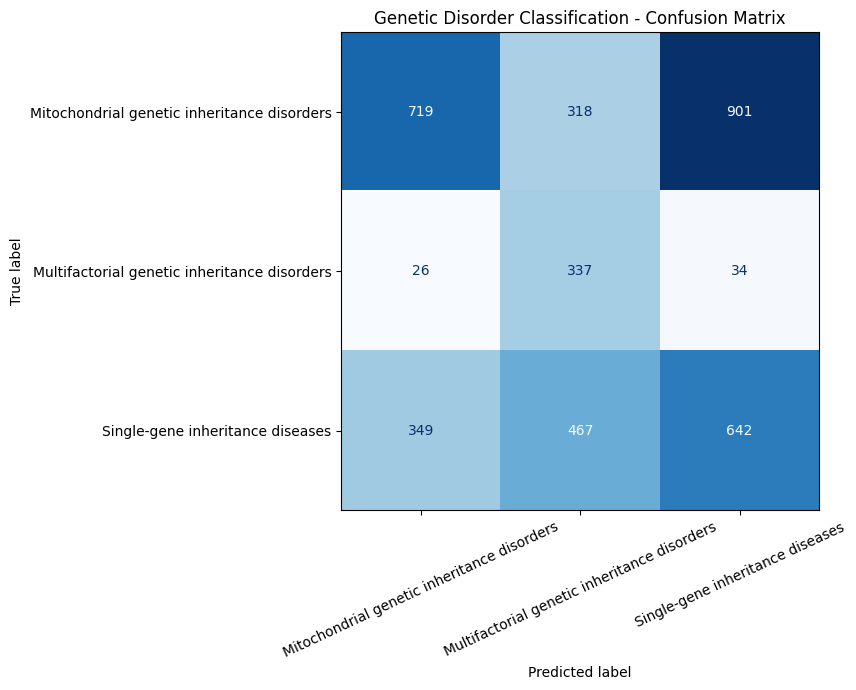

In [55]:
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=model.classes_
)

fig, ax = plt.subplots(figsize=(10, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=25,
    colorbar=False
)
print("genetic disorder classification")
plt.title("Genetic Disorder Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [56]:
with open("app.py", "r") as f:
    print(f.read())

import streamlit as st
import pandas as pd
import numpy as np
import requests
import json
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Genetic Disorder Classification",
    page_icon="🧬",
    layout="wide"
)

st.title("🧬 Genetic Disorder Risk Classification System")
st.write(
    "Educational ML prototype for preliminary genetic disorder "
    "category classification. This is not a medical diagnosis."
)

API_URL = "https://dingo-paprika-uneaten.ngrok-free.dev/predict"

with open("feature_info.json", "r") as f:
    feature_info = json.load(f)

st.header("Patient Information")
st.write("Enter the available patient attributes below.")

with st.form("patient_form"):
    patient_data = {}

    for feature, info in feature_info.items():
        if info["type"] == "numeric":
            default = info.get("default", 0.0)
            patient_data[feature] = st.number_input(
                feature,
                value=float(default),
                key=feature
     

In [57]:

%%writefile app.py
import streamlit as st
import pandas as pd
import requests
import json
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Genetic Disorder Classification",
    page_icon="🧬",
    layout="wide"
)

st.title("🧬 Genetic Disorder Risk Classification System")
st.write(
    "Educational ML prototype for genetic disorder category "
    "classification. This is not a medical diagnosis."
)

API_URL = "https://dingo-paprika-uneaten.ngrok-free.dev/predict"

# Load feature information
with open("feature_info.json", "r") as f:
    feature_info = json.load(f)

# ---------------- PATIENT PREDICTION ----------------

st.header("Patient Information")
st.write("Enter the available patient attributes below.")

with st.form("patient_form"):
    patient_data = {}

    for feature, info in feature_info.items():
        if info["type"] == "numeric":
            patient_data[feature] = st.number_input(
                feature,
                value=float(info.get("default", 0.0)),
                key=feature
            )
        else:
            options = info.get("options", [])

            if options:
                patient_data[feature] = st.selectbox(
                    feature,
                    options=options,
                    key=feature
                )
            else:
                patient_data[feature] = st.text_input(
                    feature,
                    key=feature
                )

    submitted = st.form_submit_button("Predict Disorder Category")

if submitted:
    try:
        response = requests.post(
            API_URL,
            json=patient_data,
            headers={"ngrok-skip-browser-warning": "true"},
            timeout=60
        )

        if response.status_code == 200:
            result = response.json()

            st.subheader("Prediction Result")
            st.success(result["predicted_category"])

            probabilities = result.get("probabilities", {})

            if probabilities:
                probability_df = pd.DataFrame({
                    "Category": list(probabilities.keys()),
                    "Probability": list(probabilities.values())
                })

                probability_df["Percentage"] = (
                    probability_df["Probability"] * 100
                )

                st.subheader("Class Probability Estimates")

                st.bar_chart(
                    probability_df.set_index("Category")["Percentage"]
                )

                st.dataframe(
                    probability_df[["Category", "Percentage"]],
                    use_container_width=True,
                    hide_index=True
                )

                st.caption(
                    "Probabilities are model estimates and are not "
                    "calibrated clinical risk values."
                )
        else:
            st.error(
                f"API error ({response.status_code}): {response.text}"
            )

    except requests.exceptions.RequestException as e:
        st.error(
            "Could not connect to the Flask API. Check that Flask "
            "and the ngrok tunnel are running."
        )
        st.code(str(e))

# ---------------- MODEL PERFORMANCE ----------------

st.divider()
st.header("📊 Model Performance Evaluation")
st.write(
    "Evaluation on the held-out validation dataset. "
    "These results describe model performance, not clinical accuracy."
)

try:
    with open("model_evaluation.json", "r") as f:
        results = json.load(f)

    # Metric cards
    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Accuracy", f"{results['accuracy'] * 100:.2f}%")
    c2.metric("Macro Precision", f"{results['macro_precision']:.4f}")
    c3.metric("Macro Recall", f"{results['macro_recall']:.4f}")
    c4.metric("Macro F1-score", f"{results['macro_f1']:.4f}")

    # Classification report
    st.subheader("Classification Report")

    report = results["classification_report"]

    class_names = results["classes"]

    report_rows = []
    for class_name in class_names:
        row = report[class_name]
        report_rows.append({
            "Category": class_name,
            "Precision": row["precision"],
            "Recall": row["recall"],
            "F1-score": row["f1-score"],
            "Support": int(row["support"])
        })

    report_df = pd.DataFrame(report_rows)

    st.dataframe(
        report_df.round(3),
        use_container_width=True,
        hide_index=True
    )

    # Compare macro metrics
    st.subheader("Macro Performance Comparison")

    metric_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Score": [
            results["macro_precision"],
            results["macro_recall"],
            results["macro_f1"]
        ]
    })

    st.bar_chart(metric_df.set_index("Metric"))

    # Actual confusion matrix
    st.subheader("Confusion Matrix")

    cm = results["confusion_matrix"]
    classes = results["classes"]

    fig, ax = plt.subplots(figsize=(10, 6))

    image = ax.imshow(cm, cmap="Blues")
    fig.colorbar(image, ax=ax)

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=25, ha="right")
    ax.set_yticklabels(classes)

    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")
    ax.set_title("Logistic Regression Confusion Matrix")

    threshold = max(max(row) for row in cm) / 2

    for i in range(len(cm)):
        for j in range(len(cm[i])):
            ax.text(
                j, i, str(cm[i][j]),
                ha="center",
                va="center",
                color="white" if cm[i][j] > threshold else "black"
            )

    plt.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

    st.caption(
        "Rows represent actual categories; columns represent predicted "
        "categories. Diagonal values are correct predictions."
    )

except FileNotFoundError:
    st.warning(
        "Evaluation file not found. Run the notebook cell that creates "
        "model_evaluation.json, then restart or refresh this app."
    )

except (KeyError, ValueError, TypeError) as e:
    st.error(f"Could not display evaluation results: {e}")

st.divider()
st.caption(
    "Educational project only. Predictions must not be used to diagnose "
    "genetic disorders or make medical decisions."
)


Overwriting app.py


In [58]:
import subprocess
import time
import requests

subprocess.run(
    ["bash", "-lc", "pkill -f '[s]treamlit run app.py'"],
    check=False
)

time.sleep(2)

log_file = open("/tmp/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--server.allowedHosts", "*"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

response = requests.get(
    "http://127.0.0.1:8501/_stcore/health",
    timeout=10
)

print("Streamlit health:", response.status_code, response.text)
print("Open your existing Colab proxy URL to view the updated dashboard.")

Streamlit health: 200 ok
Open your existing Colab proxy URL to view the updated dashboard.


In [62]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Model 1: Existing Logistic Regression pipeline
# Note: The step name is 'classifier', so we use classifier__class_weight
models = {
    "Logistic Regression": model,
    "Balanced Logistic Regression": clone(model).set_params(
        classifier__class_weight="balanced"
    ),
}

# Model 2: Extra Trees, using the same preprocessing pipeline
# If et_model is your already-trained full pipeline, use it.
if "et_model" in globals():
    models["Extra Trees"] = et_model

results_list = []

for name, candidate in models.items():
    # Train only models that have not already been fitted
    if name == "Balanced Logistic Regression":
        candidate.fit(X_train, y_train)

    predictions = candidate.predict(X_val)

    results_list.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results_list)
print(comparison_df.round(4).to_string(index=False))

                       Model  Accuracy  Macro Precision  Macro Recall  Macro F1
         Logistic Regression    0.4477           0.4549        0.5534    0.4470
Balanced Logistic Regression    0.4477           0.4549        0.5534    0.4470
                 Extra Trees    0.5827           0.5468        0.4507    0.4534


EXTRA TREES — CLASSIFICATION REPORT
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.59      0.86      0.70      1938
Multifactorial genetic inheritance disorders       0.49      0.17      0.25       397
            Single-gene inheritance diseases       0.56      0.32      0.41      1458

                                    accuracy                           0.58      3793
                                   macro avg       0.55      0.45      0.45      3793
                                weighted avg       0.57      0.58      0.54      3793



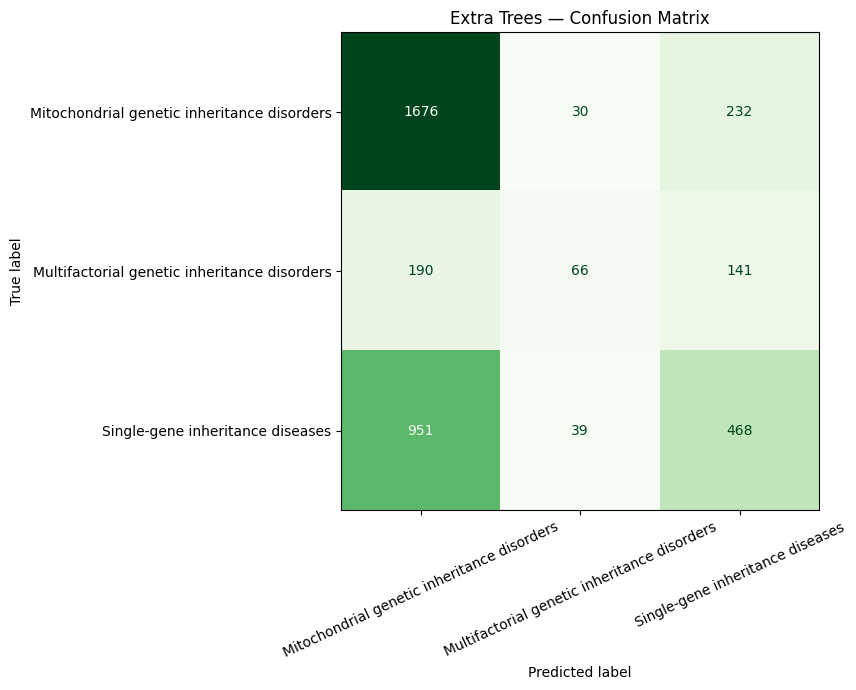

In [63]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use your existing Extra Trees model
et_predictions = et_model.predict(X_val)

print("EXTRA TREES — CLASSIFICATION REPORT")
print(classification_report(
    y_val,
    et_predictions,
    labels=et_model.classes_,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    et_predictions,
    labels=et_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=et_model.classes_
)

disp.plot(
    ax=ax,
    cmap="Greens",
    xticks_rotation=25,
    colorbar=False
)

plt.title("Extra Trees — Confusion Matrix")
plt.tight_layout()
plt.show()


In [64]:
import joblib

joblib.dump(et_model, "genetic_disorder_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [73]:
import requests

url = "http://127.0.0.1:5000/"

response = requests.get(url, timeout=5)

print("Status code:", response.status_code)
print("Response:", response.json())

INFO:werkzeug:127.0.0.1 - - [20/Oct/2026 15:24:21] "GET / HTTP/1.1" 200 -


Status code: 200
Response: {'message': 'Genetic Disorder Prediction API is running'}


In [75]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0



2026-10-20 15:30:33.563 Port 8501 is not available


In [76]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Streamlit status:", r.status_code)
except Exception as e:
    print("Streamlit not responding:", e)

Streamlit status: 200


In [77]:
from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>